In [ ]:
!wget -O /content/df.csv "https://huggingface.co/datasets/locuoco/the-biggest-spam-ham-phish-email-dataset-300000/resolve/main/df.csv"


--2026-10-23 15:58:33--  https://huggingface.co/datasets/locuoco/the-biggest-spam-ham-phish-email-dataset-300000/resolve/main/df.csv
Resolving huggingface.co (huggingface.co)... 13.35.202.121, 13.35.202.40, 13.35.202.97, ...
Connecting to huggingface.co (huggingface.co)|13.35.202.121|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/698d79f0b086396b164b6811/03f8b8638aa1e4ef8776b9ba0f15ec2803c36a99e2f30f87069fb6e1b67cef24?xip=1WVvn8ro0AU&response-content-type=text%2Fcsv%3B+charset%3Dutf-8&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27df.csv%3B+filename%3D%22df.csv%22%3B&X-Xet-Cas-Uid=public&user_id=public&Expires=1792774713&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjk4ZDc5ZjBiMDg2Mzk2YjE2NGI2ODExLzAzZjhiODYzOGFhMWU0ZWY4Nzc2YjliYTBmMTVlYzI4MDNjMzZhOTllMmYzMGY4NzA2OWZiNmUxYjY3Y2VmMjRcXD94aXA9MVdWdm44cm8wQVUmcmVzcG9uc2UtY29udGVudC10eXBlPSomcmVzcG9uc2UtY2

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/df.csv')

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nLabel distribution:")
print(df['label'].value_counts().sort_index())

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEmail length statistics:")
print(df['text'].str.len().describe())

Dataset shape: (365448, 2)

Columns: ['label', 'text']

First five rows:


,label,text
0,0,wrong bill grace i ' ll forward original messa...
1,0,i have continued the hilcorp old ocean deal da...
2,0,several related issues have resulted in an inc...
3,0,one year rate for this one will be escapenumbe...
4,0,attached is the weekly deal report for escapen...



Label distribution:
label
0    168455
1     42845
2    154148
Name: count, dtype: int64

Missing values:
label    0
text     2
dtype: int64

Duplicate rows: 84490

Email length statistics:
count    3.654460e+05
mean     1.703703e+03
std      2.223086e+04
min      1.000000e+00
25%      3.430000e+02
50%      7.630000e+02
75%      1.737000e+03
max      1.151031e+07
Name: text, dtype: float64


In [ ]:
for label in sorted(df['label'].dropna().unique()):
    examples = df.loc[df['label'] == label, 'text'].dropna()

    if len(examples) > 0:
        print(f"\nLabel {label}:")
        print(examples.iloc[0][:200])

print("\nMedian email length by label:")
print(df.groupby('label')['text'].apply(
    lambda x: x.dropna().str.len().median()
))


Label 0:
wrong bill grace i ' ll forward original message from rodriguez grace sent friday june escapenumber escapenumber escapenumber escapenumber am to fitzpatrick amy williams bill subject re wolf reply rep

Label 1:
link dwl g 510 802 11 g wireless pci lan adapter 39 85 39 85 dwl g 510 high speed 2 4 ghz 802 11 g wireless pci lan adapter ieee 802 11 g standardupto 54 mbpsoperating frequency range 2 4 ghz ideal so

Label 2:
here you can buy goods for escapenumber escapenumber of their real value you wonder why we have such good prices everything is very easy we are carders we buy goods in online shops onstolen credit car

Median email length by label:
label
0    986.0
1    391.0
2    679.0
Name: text, dtype: float64


In [ ]:
df = df.dropna(subset=['text', 'label']).copy()

# Keep the first 5,000 characters
df['text'] = df['text'].astype(str).str[:5000]

# Remove an unwanted dataset artifact
df['text'] = df['text'].str.replace(
    'escapenumber', ' ', regex=False
)

# Convert text to lowercase
df['text'] = df['text'].str.lower()

# Keep only letters and spaces
df['text'] = df['text'].str.replace(
    r'[^a-z\s]', ' ', regex=True
)

# Remove extra spaces
df['text'] = df['text'].str.replace(
    r'\s+', ' ', regex=True
).str.strip()

# Remove very short emails and duplicates
df = df[df['text'].str.len() > 20].copy()
df = df.drop_duplicates(subset=['text', 'label']).copy()

print("Cleaned dataset shape:", df.shape)
print("\nLabels after cleaning:")
print(df['label'].value_counts().sort_index())

Cleaned dataset shape: (246025, 2)

Labels after cleaning:
label
0    111090
1     42701
2     92234
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

if len(df) < 100000:
    raise ValueError(
        f"Only {len(df)} rows remain. Reduce train_size to continue."
    )

sample, _ = train_test_split(
    df,
    train_size=100000,
    stratify=df['label'],
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    sample['text'],
    sample['label'],
    test_size=0.2,
    stratify=sample['label'],
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

Training samples: 80000
Testing samples: 20000

Training label distribution:
label
0    36123
1    13885
2    29992
Name: count, dtype: int64


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words='english'
)

X_train_t = tfidf.fit_transform(X_train)
X_test_t = tfidf.transform(X_test)

print("Training feature matrix:", X_train_t.shape)
print("Testing feature matrix:", X_test_t.shape)

Training feature matrix: (80000, 20000)
Testing feature matrix: (20000, 20000)


In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000)
}

trained_models = {}
results = []

for name, model in models.items():

    model.fit(X_train_t, y_train)

    predictions = model.predict(X_test_t)

    trained_models[name] = model

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test, predictions, average='macro'
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    print(f"\n{'=' * 40}")
    print(name)
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

results_df = pd.DataFrame(results)
display(results_df.sort_values("Macro F1", ascending=False))


Multinomial Naive Bayes
Accuracy: 0.8784
Macro F1: 0.8423

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      9031
           1       0.88      0.62      0.72      3471
           2       0.82      0.90      0.86      7498

    accuracy                           0.88     20000
   macro avg       0.88      0.83      0.84     20000
weighted avg       0.88      0.88      0.87     20000


Logistic Regression
Accuracy: 0.9171
Macro F1: 0.8938

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      9031
           1       0.90      0.74      0.81      3471
           2       0.87      0.93      0.90      7498

    accuracy                           0.92     20000
   macro avg       0.91      0.88      0.89     20000
weighted avg       0.92      0.92      0.92     20000



,Model,Accuracy,Macro F1
1,Logistic Regression,0.91710,0.893762
0,Multinomial Naive Bayes,0.87845,0.842330


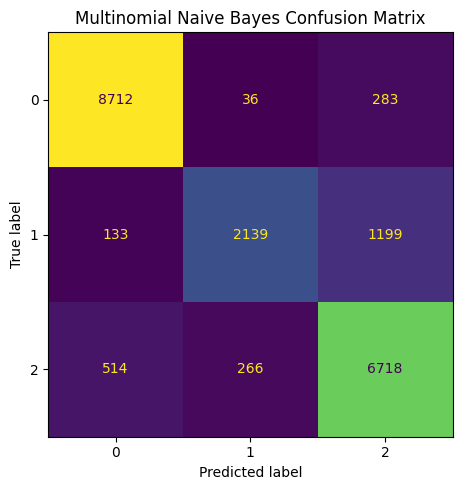

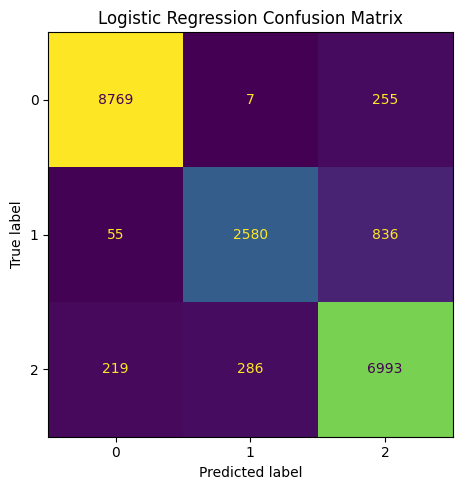

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, model in trained_models.items():

    predictions = model.predict(X_test_t)

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        ax=ax,
        colorbar=False
    )

    ax.set_title(f"{name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:
import joblib

results_df = results_df.sort_values(
    "Macro F1", ascending=False
)

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model based on macro F1:", best_name)
display(results_df)

joblib.dump(
    best_model,
    "/content/model3_email_classifier.joblib"
)

joblib.dump(
    tfidf,
    "/content/model3_tfidf_vectorizer.joblib"
)

results_df.to_csv(
    "/content/model3_evaluation.csv",
    index=False
)

print("Model and vectorizer saved successfully.")

Best model based on macro F1: Logistic Regression


,Model,Accuracy,Macro F1
1,Logistic Regression,0.91710,0.893762
0,Multinomial Naive Bayes,0.87845,0.842330


Model and vectorizer saved successfully.


In [ ]:
example_emails = [
    "Congratulations, you have won a prize. Click here to claim your reward.",
    "Hi team, please find the meeting notes attached. See you tomorrow.",
    "Your account needs verification. Follow this link immediately to avoid suspension."
]

example_features = tfidf.transform(example_emails)
predictions = best_model.predict(example_features)

for email, prediction in zip(example_emails, predictions):
    print("Email:", email)
    print("Predicted label:", prediction)
    print("-" * 50)

Email: Congratulations, you have won a prize. Click here to claim your reward.
Predicted label: 2
--------------------------------------------------
Email: Hi team, please find the meeting notes attached. See you tomorrow.
Predicted label: 0
--------------------------------------------------
Email: Your account needs verification. Follow this link immediately to avoid suspension.
Predicted label: 1
--------------------------------------------------


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

save_folder = '/content/drive/MyDrive/ML_Project'
os.makedirs(save_folder, exist_ok=True)

for filename in [
    'model3_email_classifier.joblib',
    'model3_tfidf_vectorizer.joblib',
    'model3_evaluation.csv'
]:
    shutil.copy2(
        f'/content/{filename}',
        f'{save_folder}/{filename}'
    )

print("Files saved to:", save_folder)

Mounted at /content/drive
Files saved to: /content/drive/MyDrive/ML_Project
